# Workflow changes: final scan results

This notebook explains what was collected, what the checks measured, what the completed scans show, and what remains to be addressed.

In [1]:
from pathlib import Path
import json, collections, hashlib, difflib, sys, html
from urllib.parse import quote
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

experiment_dir = Path.cwd()
OUT = experiment_dir / 'paper_a_outputs'
HERE = Path(ANALYSIS_DIR) if 'ANALYSIS_DIR' in globals() else experiment_dir / 'Final Results'
TABLES, FIGURES = HERE / 'tables', HERE / 'figures'
TABLES.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)
tables = {}
SEED = 20261015

def table(name, frame):
    tables[name] = frame.copy()
    frame.to_csv(TABLES / (name + '.csv'), index=False)
    display(frame)

run_meta = json.loads((OUT/'full_run/run_metadata.json').read_text())
verification = json.loads((OUT/'full_run/verification.json').read_text())
assembly = json.loads((OUT/'assembly_counts.json').read_text())
assert run_meta['phase'] == 'finished' and verification['passed']
assert assembly['pending_prs'] == 0
print('Saved full-run verification passed. Input SHA-256:', run_meta['input_sha256'])
print('This notebook uses compact pair metadata and the saved scans.')


Saved full-run verification passed. Input SHA-256: 291eaff629406ea1d1f02ad913570166a8136b0422abfc625412393c8ebe38f9
This notebook checks current table identities/counts, but does not rehash the 14 GB input again.


## 1. Load the population and check the units

In [2]:
summary_cols = ['pair_id','source','repo','commit_or_pr','agent_name','author_class','path',
 'change_type','conversion_status','scan_status','all_oracles_complete','all_checks_decidable','context_gaps']
p = pd.read_parquet(OUT/'full_run/pairs_summary.parquet', columns=summary_cols)
meta_cols = ['pair_id','pr_number','base_sha','head_sha','before_path','after_path','before_exists',
 'after_exists','metadata_error','snapshot_validation','created_at','merged_at','link_quality']
meta = pd.read_parquet(OUT/'pairs_metadata.parquet', columns=meta_cols)
assert p.pair_id.is_unique and meta.pair_id.is_unique and p.pair_id.equals(meta.pair_id)
p = p.merge(meta, on='pair_id', validate='one_to_one', sort=False)
p['change_key'] = p.source + ':' + p.repo + ':' + p.commit_or_pr.astype(str)
decoded = p.scan_status.map(json.loads)
ORACLES = ['zizmor','actionlint','custom','change']
for oracle in ORACLES:
    p[oracle+'_ok'] = decoded.map(lambda d: d.get(oracle) == 'analyzed')
p['has_context_gap'] = p.context_gaps.map(lambda v: bool(json.loads(v)))
p['metadata_qualified'] = p.metadata_error.fillna('').ne('')
p['lock_suffix'] = p.path.str.lower().str.endswith(('.lock.yml','.lock.yaml'))
fcols = ['pair_id','oracle','rule_id','status','severity','match_basis','needs_review','rule_group']
f = pd.read_parquet(OUT/'full_run/findings.parquet', columns=fcols)
f['finding_index'] = np.arange(len(f))
assert len(p) == verification['counts']['input_pairs']
assert len(f) == verification['counts']['findings']
assert f.pair_id.isin(p.pair_id).all()
catalog = pd.read_csv(OUT/'rule_catalog.csv').fillna('')
assert set(f.rule_id).issubset(set(catalog.rule_id))
funnel = pd.DataFrame([
 ['Selected AIDev PRs',assembly['selected_prs']],
 ['Recovered AIDev PR histories',assembly['recovered_prs']],
 ['Excluded AIDev PR histories',assembly['excluded_prs']],
 ['All candidate workflow-file records',len(p)],
 ['Ready workflow-file pairs',int(p.conversion_status.eq('ready').sum())],
 ['Explicitly excluded file records',int(p.conversion_status.eq('excluded').sum())],
 ['File pairs with all four check categories complete',int(p.all_oracles_complete.sum())],
 ['File pairs with metadata qualifications',int(p.metadata_qualified.sum())],
], columns=['Stage / unit','Count'])
table('01_funnel',funnel)
scope = p.groupby(['source','author_class'],dropna=False).agg(
 file_records=('pair_id','size'),repos=('repo','nunique'),changes=('change_key','nunique')).reset_index()
table('02_source_scope',scope)
source_totals=p.groupby('source').agg(file_records=('pair_id','size'),repos=('repo','nunique'),changes=('change_key','nunique')).reset_index()
table('02b_source_totals',source_totals)
print('A change means PR for AIDev and commit for SWE-chat. The source table is not a human-control table.')
print('A commit may have files with different attribution classes: change counts across attribution rows are not additive.')
print('Recovered AIDev PR histories without a ready net YAML pair:',assembly['recovered_prs']-p.loc[p.source.eq('aidev_v5') & p.conversion_status.eq('ready'),'change_key'].nunique())


,Stage / unit,Count
0,Selected AIDev PRs,25889
1,Recovered AIDev PR histories,24933
2,Excluded AIDev PR histories,956
3,All candidate workflow-file records,248253
4,Ready workflow-file pairs,241646
5,Explicitly excluded file records,6607
6,File pairs with all four check categories comp...,239731
7,File pairs with metadata qualifications,374


,source,author_class,file_records,repos,changes
0,aidev_v5,agent,248110,5097,25202
1,swechat,agent,109,31,94
2,swechat,mixed,34,14,29


,source,file_records,repos,changes
0,aidev_v5,248110,5097,25202
1,swechat,143,36,119


A change means PR for AIDev and commit for SWE-chat. The source table is not a human-control table.
A commit may have files with different attribution classes: change counts across attribution rows are not additive.
Recovered AIDev PR histories without a ready net YAML pair: 684


## 2. What each check means

| Check | What it measures | What a zero does not prove |
|---|---|---|
| zizmor | Security patterns detected in workflow YAML | No exploitable vulnerability, task success, or policy compliance |
| actionlint | Workflow syntax, expressions and consistency | Workflow executes successfully; shellcheck/pyflakes were disabled |
| Custom R1–R11 | Literal candidate requirements, when the implementation considers them applicable | Repository adoption, universal applicability, or semantic quality |
| Relative change predicates | Broadened permissions, removed lexical test/lint steps, newly literal `continue-on-error` | Remaining checks are equivalent, changes are unjustified, or all permissions were knowable |

**Introduced:** unmatched after-state finding. **Fixed:** unmatched before-state finding. **Persisted:** matched across states. This is a static comparison.


In [3]:
counts = f.groupby(['pair_id','oracle','status']).size().unstack(['oracle','status'],fill_value=0)
for oracle in ORACLES:
    for state in ['introduced','fixed','persisted']:
        values = counts[(oracle,state)] if (oracle,state) in counts else pd.Series(dtype=float)
        p[oracle+'_'+state] = p.pair_id.map(values).fillna(0).where(p[oracle+'_ok'])

def rates(frame, label):
    rows=[]
    ready = frame[frame.conversion_status.eq('ready')]
    for oracle in ORACLES:
        good = ready[ready[oracle+'_ok']]
        # A PR/commit is eligible only when every ready file in this scope completed this tool.
        scope = ready.groupby('change_key').size().rename('ready_files')
        observed = good.groupby('change_key').agg(scanned=('pair_id','size'),
            introduced=(oracle+'_introduced','sum'), fixed=(oracle+'_fixed','sum'))
        complete = observed.join(scope).query('scanned == ready_files')
        n=len(good); k=int(good[oracle+'_introduced'].gt(0).sum())
        rows.append(dict(scope=label,oracle=oracle,ready_files=len(ready),analyzed_files=n,
            files_with_introduced=k,file_rate_pct=100*k/n if n else np.nan,
            files_with_fixed=int(good[oracle+'_fixed'].gt(0).sum()),
            introduced_instances=int(good[oracle+'_introduced'].sum()),
            fixed_instances=int(good[oracle+'_fixed'].sum()),
            persisted_instances=int(good[oracle+'_persisted'].sum()),
            complete_changes=len(complete),changes_with_introduced=int(complete.introduced.gt(0).sum()),
            change_rate_pct=100*complete.introduced.gt(0).mean() if len(complete) else np.nan,
            context_gap_files=int(good.has_context_gap.sum())))
    return pd.DataFrame(rows)

overall = pd.concat([rates(g,source) for source,g in p.groupby('source')],ignore_index=True)
table('03_tool_rates',overall.round(2))
status_rows=[]
for source,g in p.groupby('source'):
    ready=g[g.conversion_status.eq('ready')]
    for oracle in ORACLES:
        status_rows.append(dict(source=source,oracle=oracle,ready_pairs=len(ready),
            successful_comparisons=int(ready[oracle+'_ok'].sum()),
            incomplete_comparisons=int((~ready[oracle+'_ok']).sum())))
table('04_tool_coverage',pd.DataFrame(status_rows))


,scope,oracle,ready_files,analyzed_files,files_with_introduced,file_rate_pct,files_with_fixed,introduced_instances,fixed_instances,persisted_instances,complete_changes,changes_with_introduced,change_rate_pct,context_gap_files
0,aidev_v5,zizmor,241504,239772,19721,8.22,12519,89122,52857,885992,23606,8987,38.07,24216
1,aidev_v5,actionlint,241504,241504,5419,2.24,5098,12108,9583,62703,24249,2343,9.66,24505
2,aidev_v5,custom,241504,240775,12566,5.22,8552,39443,18823,580242,23794,6427,27.01,24482
3,aidev_v5,change,241504,240992,25047,10.39,0,83244,0,0,23911,7381,30.87,24505
4,swechat,zizmor,142,142,44,30.99,13,168,39,996,119,40,33.61,77
5,swechat,actionlint,142,142,4,2.82,2,6,2,28,119,4,3.36,77
6,swechat,custom,142,142,27,19.01,9,105,14,534,119,24,20.17,77
7,swechat,change,142,142,19,13.38,0,45,0,0,119,16,13.45,77


,source,oracle,ready_pairs,successful_comparisons,incomplete_comparisons
0,aidev_v5,zizmor,241504,239772,1732
1,aidev_v5,actionlint,241504,241504,0
2,aidev_v5,custom,241504,240775,729
3,aidev_v5,change,241504,240992,512
4,swechat,zizmor,142,142,0
5,swechat,actionlint,142,142,0
6,swechat,custom,142,142,0
7,swechat,change,142,142,0


## 3. Which rules account for the findings?

Instances, positive files, and positive PRs answer different questions. Several flags in one file count as several instances but only one positive file.

In [4]:
rule_totals = f.groupby(['oracle','rule_id','status']).size().unstack('status',fill_value=0).reset_index()
positive_files = f[f.status.eq('introduced')].groupby('rule_id').pair_id.nunique().rename('files_with_introduced')
rule_totals = rule_totals.merge(positive_files,on='rule_id',how='left').fillna({'files_with_introduced':0})
rule_totals = rule_totals.merge(catalog[['rule_id','statement','source_reference','source','qualification']],on='rule_id',validate='many_to_one')
rule_totals = rule_totals.sort_values(['oracle','introduced'],ascending=[True,False])
table('05_rule_totals',rule_totals)
table('06_severity_counts',f.groupby(['oracle','severity','status']).size().rename('instances').reset_index())
review = f.groupby(['oracle','status']).agg(instances=('pair_id','size'),
 flagged_for_review=('needs_review','sum')).reset_index()
table('07_matching_review',review)
print('A review flag is not a confirmed matching error. Many unmatched findings on modified files are flagged conservatively.')


,oracle,rule_id,fixed,introduced,persisted,files_with_introduced,statement,source_reference,source,qualification
4,actionlint,A_expression,3187,6397,24743,1957.0,Resolve actionlint expression diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
11,actionlint,A_runner_label,1725,2271,13121,1321.0,Resolve actionlint runner_label diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
0,actionlint,A_action,3724,1798,10293,1062.0,Resolve actionlint action diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
13,actionlint,A_syntax_check,351,649,1801,447.0,Resolve actionlint syntax_check diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
10,actionlint,A_permissions,76,430,10827,421.0,Resolve actionlint permissions diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
7,actionlint,A_if_cond,125,275,883,193.0,Resolve actionlint if_cond diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
6,actionlint,A_id,136,137,0,137.0,Resolve actionlint id diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
3,actionlint,A_events,57,90,366,81.0,Resolve actionlint events diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
8,actionlint,A_job_needs,92,38,69,15.0,Resolve actionlint job_needs diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."
1,actionlint,A_deprecated_commands,33,13,505,13.0,Resolve actionlint deprecated_commands diagnostic,Pinned actionlint 1.7.12,https://github.com/rhysd/actionlint/blob/v1.7....,"Isolated YAML, no shellcheck/pyflakes or repos..."


,oracle,severity,status,instances
0,actionlint,error,fixed,9585
1,actionlint,error,introduced,12114
2,actionlint,error,persisted,62731
3,change,review,introduced,83289
4,custom,review,fixed,18837
5,custom,review,introduced,39548
6,custom,review,persisted,580776
7,zizmor,High,fixed,32808
8,zizmor,High,introduced,58541
9,zizmor,High,persisted,479839


,oracle,status,instances,flagged_for_review
0,actionlint,fixed,9585,8028
1,actionlint,introduced,12114,7841
2,actionlint,persisted,62731,12410
3,change,introduced,83289,83289
4,custom,fixed,18837,8113
5,custom,introduced,39548,3465
6,custom,persisted,580776,0
7,zizmor,fixed,52896,36043
8,zizmor,introduced,89290,38069
9,zizmor,persisted,886988,158901


A review flag is not a confirmed matching error. Many unmatched findings on modified files are flagged conservatively.


## 4. Sensitivity to added files, one large repository, and unpinned actions

These are descriptive subgroup checks, not independent replications. Each subgroup uses its own eligible denominator.


In [5]:
a = p[p.source.eq('aidev_v5')].copy()
subgroups = [('All AIDev',a),('AIDev excluding github/gh-aw',a[a.repo.ne('github/gh-aw')])]
added_changes=set(a.loc[a.change_type.eq('added'),'change_key'])
subgroups += [('AIDev PRs with no added workflow',a[~a.change_key.isin(added_changes)]),
 ('AIDev excluding github/gh-aw and PRs adding workflows',a[a.repo.ne('github/gh-aw') & ~a.change_key.isin(added_changes)])]
subgroups += [('AIDev '+str(kind),g) for kind,g in a.groupby('change_type',dropna=True)]
subgroups += [('AIDev .lock.yml/.lock.yaml suffix',a[a.lock_suffix]),
              ('AIDev other suffixes',a[~a.lock_suffix])]
sensitivity=pd.concat([rates(g,name) for name,g in subgroups],ignore_index=True)
table('08_subgroup_rates',sensitivity.round(2))
table('08b_security_sensitivity',sensitivity[sensitivity.oracle.eq('zizmor')].round(2))
without = a.copy()
for state in ['introduced','fixed','persisted']:
    z_no_pin=f[f.oracle.eq('zizmor') & f.status.eq(state) & f.rule_id.ne('Z_unpinned_uses')].groupby('pair_id').size()
    without['zizmor_'+state]=without.pair_id.map(z_no_pin).fillna(0).where(without.zizmor_ok)
unpinned=pd.concat([rates(a,'All zizmor rules'),rates(without,'Excluding unpinned-uses')])
table('09_without_unpinned',unpinned[unpinned.oracle.eq('zizmor')].round(2))
print('Filename suffixes are a proxy for generated output. We check the gh-aw generation header below.')


,scope,oracle,ready_files,analyzed_files,files_with_introduced,file_rate_pct,files_with_fixed,introduced_instances,fixed_instances,persisted_instances,complete_changes,changes_with_introduced,change_rate_pct,context_gap_files
0,All AIDev,zizmor,241504,239772,19721,8.22,12519,89122,52857,885992,23606,8987,38.07,24216
1,All AIDev,actionlint,241504,241504,5419,2.24,5098,12108,9583,62703,24249,2343,9.66,24505
2,All AIDev,custom,241504,240775,12566,5.22,8552,39443,18823,580242,23794,6427,27.01,24482
3,All AIDev,change,241504,240992,25047,10.39,0,83244,0,0,23911,7381,30.87,24505
4,AIDev excluding github/gh-aw,zizmor,60889,60095,16245,27.03,10005,74979,40288,467609,19031,8177,42.97,24195
5,AIDev excluding github/gh-aw,actionlint,60889,60889,3379,5.55,3817,7293,7346,31003,19465,2118,10.88,24484
6,AIDev excluding github/gh-aw,custom,60889,60271,10823,17.96,7218,36215,16885,200855,19072,5717,29.98,24461
7,AIDev excluding github/gh-aw,change,60889,60487,12447,20.58,0,44597,0,0,19188,6145,32.03,24484
8,AIDev PRs with no added workflow,zizmor,194599,193187,7268,3.76,6919,24383,24358,713435,18112,3810,21.04,14996
9,AIDev PRs with no added workflow,actionlint,194599,194599,2552,1.31,3073,4087,5660,49670,18593,913,4.91,15250


,scope,oracle,ready_files,analyzed_files,files_with_introduced,file_rate_pct,files_with_fixed,introduced_instances,fixed_instances,persisted_instances,complete_changes,changes_with_introduced,change_rate_pct,context_gap_files
0,All AIDev,zizmor,241504,239772,19721,8.22,12519,89122,52857,885992,23606,8987,38.07,24216
4,AIDev excluding github/gh-aw,zizmor,60889,60095,16245,27.03,10005,74979,40288,467609,19031,8177,42.97,24195
8,AIDev PRs with no added workflow,zizmor,194599,193187,7268,3.76,6919,24383,24358,713435,18112,3810,21.04,14996
12,AIDev excluding github/gh-aw and PRs adding wo...,zizmor,35421,34895,5308,15.21,4887,18422,16355,346892,14113,3423,24.25,14987
16,AIDev added,zizmor,9810,9686,8326,85.96,0,51106,0,0,5565,5190,93.26,2404
20,AIDev deleted,zizmor,2712,2688,0,0.00,2491,0,16853,0,1251,0,0.00,0
24,AIDev modified,zizmor,228392,226815,11248,4.96,9881,37627,35554,882089,20524,5109,24.89,21644
28,AIDev renamed,zizmor,590,583,147,25.21,147,389,450,3903,314,110,35.03,168
32,AIDev .lock.yml/.lock.yaml suffix,zizmor,181501,180571,3725,2.06,2589,15986,13431,416227,4928,924,18.75,0
36,AIDev other suffixes,zizmor,60003,59201,15996,27.02,9930,73136,39426,469765,19342,8162,42.20,24216


,scope,oracle,ready_files,analyzed_files,files_with_introduced,file_rate_pct,files_with_fixed,introduced_instances,fixed_instances,persisted_instances,complete_changes,changes_with_introduced,change_rate_pct,context_gap_files
0,All zizmor rules,zizmor,241504,239772,19721,8.22,12519,89122,52857,885992,23606,8987,38.07,24216
0,Excluding unpinned-uses,zizmor,241504,239772,15000,6.26,9111,41948,25488,488033,23606,7558,32.02,24216


Filename suffixes are a proxy for generated output. We check the gh-aw generation header below.


## 5. Repository concentration and agent composition

File-weighted results count every file change.

,repo,analyzed_files,positive_files,changes,introduced_instances,file_rate_pct
2383,github/gh-aw,179677,3476,4765,14143.0,1.93
1210,airbytehq/airbyte,2259,877,208,3621.0,38.82
199,BerriAI/litellm,1529,61,34,95.0,3.99
2186,fern-api/fern,1347,374,142,1734.0,27.77
3379,mlflow/mlflow,1081,31,310,42.0,2.87
1842,devantler-tech/ksail,1060,139,213,456.0,13.11
1811,db-ux-design-system/core-web,1058,266,66,1032.0,25.14
672,MontrealAI/AGI-Alpha-Agent-v0,837,121,591,357.0,14.46
4706,vdaas/vald,836,3,28,23.0,0.36
3665,openclaw/openclaw,797,416,191,1816.0,52.20


,Measure,Percent
0,Largest repository share of analyzed files,74.94
1,Five largest repositories share of analyzed files,77.53
2,File-weighted introduction rate,8.22
3,Mean of repository-specific rates (each repo e...,37.77
4,Median repository-specific rate,25.00


,scope,oracle,ready_files,analyzed_files,files_with_introduced,file_rate_pct,files_with_fixed,introduced_instances,fixed_instances,persisted_instances,complete_changes,changes_with_introduced,change_rate_pct,context_gap_files
0,Claude_Code,zizmor,4393,4334,1209,27.90,748,6707,3461,44889,1153,554,48.05,1718
1,Claude_Code,actionlint,4393,4393,233,5.30,225,462,440,2396,1190,144,12.10,1724
2,Claude_Code,custom,4393,4341,786,18.11,452,2756,1260,14158,1160,403,34.74,1722
3,Claude_Code,change,4393,4344,1128,25.97,0,4433,0,0,1163,440,37.83,1724
4,Copilot,zizmor,212977,211552,11436,5.41,6867,50142,29210,642957,15412,5138,33.34,11942
5,Copilot,actionlint,212977,212977,3739,1.76,2998,9011,5504,45834,15801,1300,8.23,12197
6,Copilot,custom,212977,212502,7163,3.37,4601,21595,8672,489246,15547,3854,24.79,12179
7,Copilot,change,212977,212700,18800,8.84,0,65124,0,0,15649,4814,30.76,12197
8,Cursor,zizmor,5313,5294,1249,23.59,1414,6238,6572,36513,1052,571,54.28,2309
9,Cursor,actionlint,5313,5313,213,4.01,650,460,1074,2783,1069,132,12.35,2310


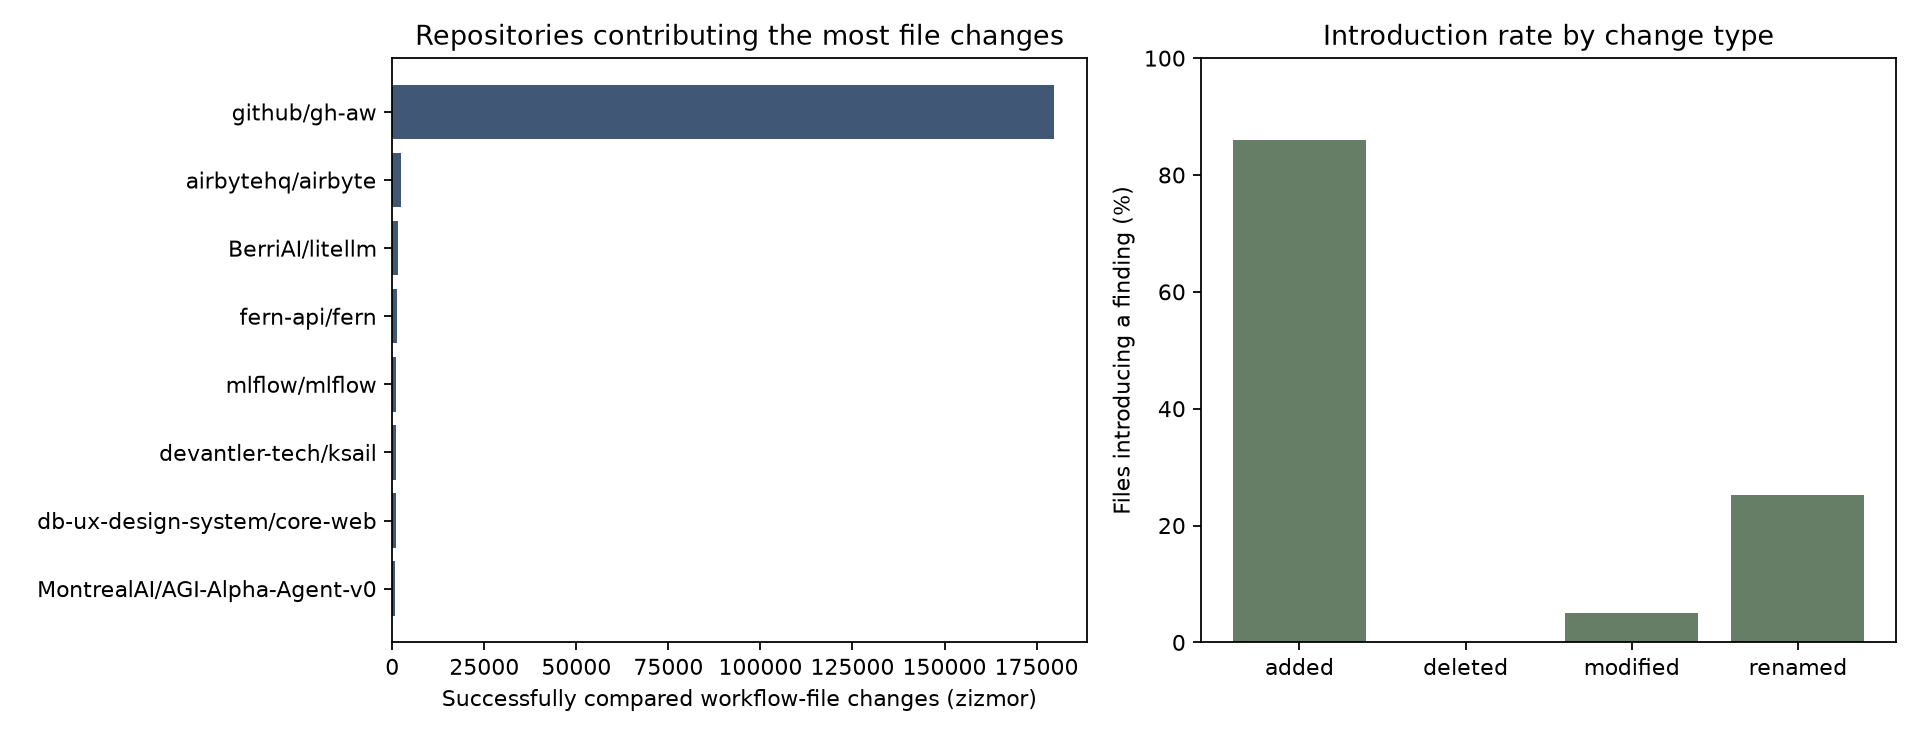

In [6]:
z=a[a.zizmor_ok].copy()
repo_stats=z.groupby('repo').agg(analyzed_files=('pair_id','size'),
    positive_files=('zizmor_introduced',lambda v:int(v.gt(0).sum())),
    changes=('change_key','nunique'),introduced_instances=('zizmor_introduced','sum')).reset_index()
repo_stats['file_rate_pct']=100*repo_stats.positive_files/repo_stats.analyzed_files
repo_stats=repo_stats.sort_values('analyzed_files',ascending=False)
table('10_largest_repositories',repo_stats.head(20).round(2))
repo_stats.to_csv(TABLES/'10_all_repositories.csv',index=False)
concentration=pd.DataFrame([
 ['Largest repository share of analyzed files',100*repo_stats.analyzed_files.iloc[0]/len(z)],
 ['Five largest repositories share of analyzed files',100*repo_stats.analyzed_files.head(5).sum()/len(z)],
 ['File-weighted introduction rate',100*z.zizmor_introduced.gt(0).mean()],
 ['Mean of repository-specific rates (each repo equal)',repo_stats.file_rate_pct.mean()],
 ['Median repository-specific rate',repo_stats.file_rate_pct.median()],
],columns=['Measure','Percent'])
table('11_repository_weighting',concentration.round(2))
agent_rates=pd.concat([rates(g,str(name)) for name,g in a.groupby('agent_name')],ignore_index=True)
table('12_agent_descriptions',agent_rates.round(2))
fig,axes=plt.subplots(1,2,figsize=(12,4.6))
top=repo_stats.head(8).iloc[::-1]
axes[0].barh(top.repo,top.analyzed_files,color='#405875')
axes[0].set_title('Repositories contributing the most file changes')
axes[0].set_xlabel('Successfully compared workflow-file changes (zizmor)')
ct=sensitivity[(sensitivity.oracle=='zizmor') & sensitivity.scope.isin(['AIDev added','AIDev modified','AIDev deleted','AIDev renamed'])]
axes[1].bar(ct.scope.str.replace('AIDev ',''),ct.file_rate_pct,color='#667d66')
axes[1].set_ylabel('Files introducing a finding (%)');axes[1].set_title('Introduction rate by change type')
axes[1].set_ylim(0,100)
fig.tight_layout();fig.savefig(FIGURES/'composition.png',dpi=160);plt.close(fig)
from PIL import Image
display(Image.open(FIGURES/'composition.png'))


## 6. Draw a review sample before reading the large workflow texts

This is a fixed-seed, deliberately stratified sample of 50 finding instances: 30 introduced, 10 fixed, and 10 persisted. It covers tools, common security rules, and relative predicates.

In [7]:
rng=np.random.default_rng(SEED)
selected=[]; used_pairs=set()
quotas=[('introduced','zizmor',16,None),('introduced','actionlint',4,None),('introduced','custom',4,None),('introduced','change',4,None),
        ('fixed','zizmor',4,None),('fixed','actionlint',3,None),('fixed','custom',2,None),
        ('persisted','zizmor',5,None),('persisted','actionlint',2,None),('persisted','custom',2,None),
        ('introduced','zizmor',2,'swechat'),('fixed','zizmor',1,'swechat'),('persisted','custom',1,'swechat')]
finding_sources=f.pair_id.map(p.set_index('pair_id').source)
for state,oracle,n,source in quotas:
    pool=f[(f.status==state)&(f.oracle==oracle)]
    if source: pool=pool[finding_sources.loc[pool.index].eq(source)]
    # Round-robin through rules ordered by frequency; random choice within each rule.
    rules=pool.rule_id.value_counts().index.tolist()
    for i in range(n):
        candidates=pool[pool.rule_id.eq(rules[i%len(rules)]) & ~pool.pair_id.isin(used_pairs)]
        if candidates.empty: candidates=pool[~pool.pair_id.isin(used_pairs)]
        if candidates.empty: candidates=pool
        chosen=int(rng.choice(candidates.index.to_numpy()))
        selected.append(chosen);used_pairs.add(f.at[chosen,'pair_id'])
sample=f.loc[selected].copy().reset_index(drop=True)
assert len(sample)==50 and len(set(selected))==50
sample['case_id']=['C'+str(i+1).zfill(3) for i in range(len(sample))]
sample=sample.merge(p[['pair_id','source','repo','commit_or_pr','agent_name','change_type','base_sha','head_sha',
    'before_path','after_path','before_exists','after_exists','metadata_qualified','snapshot_validation']],on='pair_id',validate='many_to_one')
sample=sample.merge(catalog[['rule_id','statement','source_reference','qualification']],on='rule_id',validate='many_to_one')
rule_sources=catalog.set_index('rule_id').apply(lambda r: r.source_reference if str(r.source_reference).startswith('http') else r.source,axis=1)
sample['rule_source_url']=sample.rule_id.map(rule_sources)
sample['rule_implementation_url']=sample.oracle.map(lambda o:
    'https://github.com/MekaelWasti/Agentic-Policy-Compliance/blob/main/Experiments/Data/rule_mining/mine.py'
    if o=='custom' else 'https://github.com/MekaelWasti/Agentic-Policy-Compliance/blob/main/Experiments/Policy%20Oracle%20Pipeline/paper_a/oracles.py')
table('13_review_sample_design',sample.groupby(['oracle','status']).size().rename('cases').reset_index())


,oracle,status,cases
0,actionlint,fixed,3
1,actionlint,introduced,4
2,actionlint,persisted,2
3,change,introduced,4
4,custom,fixed,2
5,custom,introduced,4
6,custom,persisted,3
7,zizmor,fixed,5
8,zizmor,introduced,18
9,zizmor,persisted,5


## 7. Workflow size and evidence extraction

This cell makes one bounded pass over before/after texts. It counts physical lines and detects the explicit gh-aw generation header. The small derived feature table is cached for subsequent notebook runs.

In [8]:
features_path=HERE/'workflow_features.parquet'
features_meta=HERE/'workflow_features_metadata.json'
snippets_path=HERE/'review_evidence.json'
cache_valid=(features_path.exists() and features_meta.exists() and snippets_path.exists()
    and json.loads(features_meta.read_text()).get('input_sha256')==run_meta['input_sha256'])
full_pairs_path = OUT / 'pairs.parquet'
if not cache_valid and not full_pairs_path.exists():
    raise FileNotFoundError(
        'Keep workflow_features.parquet, workflow_features_metadata.json, and review_evidence.json '
        'together in Final Results, or provide the full pairs.parquet to rebuild them.'
    )
if cache_valid:
    features=pd.read_parquet(features_path)
    evidence=json.loads(snippets_path.read_text())
    missing=set(sample.pair_id)-set(evidence)
    if missing and not full_pairs_path.exists():
        raise ValueError('The saved review evidence is missing some sampled pairs. Supply the original pairs.parquet to rebuild it.')
    if missing:
        q=pq.ParquetFile(full_pairs_path)
        boundaries=np.cumsum([q.metadata.row_group(i).num_rows for i in range(q.num_row_groups)])
        groups={int(np.searchsorted(boundaries,i,side='right')) for i in p.index[p.pair_id.isin(missing)]}
        for group in sorted(groups):
            for row in q.read_row_group(group,columns=['pair_id','before_yaml','after_yaml']).to_pylist():
                if row['pair_id'] in missing:
                    evidence[row['pair_id']]=dict(before=row['before_yaml'] or '',after=row['after_yaml'] or '')
        snippets_path.write_text(json.dumps(evidence),encoding='utf-8')
    assert set(sample.pair_id).issubset(evidence)
    print('Using derived size features tied to the saved input hash.')
else:
    targets=set(sample.pair_id); evidence={}; rows=[]; processed=0
    q=pq.ParquetFile(full_pairs_path)
    def lines(text):
        return text.count('\n') + int(bool(text) and not text.endswith('\n'))
    for batch in q.iter_batches(batch_size=128,columns=['pair_id','conversion_status','before_yaml','after_yaml']):
        for row in batch.to_pylist():
            if row['conversion_status']!='ready': continue
            before,after=row['before_yaml'] or '',row['after_yaml'] or ''
            marker=any('automatically generated by gh-aw' in text[:2500].lower() for text in [before,after])
            rows.append(dict(pair_id=row['pair_id'],before_lines=lines(before),after_lines=lines(after),
                             net_line_growth=lines(after)-lines(before),ghaw_generated_marker=marker))
            if row['pair_id'] in targets: evidence[row['pair_id']]=dict(before=before,after=after)
        processed+=batch.num_rows
        if processed%8192==0: print('Read workflow texts:',processed,'/',len(p),file=sys.stderr)
    features=pd.DataFrame(rows)
    assert features.pair_id.is_unique and len(features)==int(p.conversion_status.eq('ready').sum())
    features.to_parquet(features_path,index=False)
    snippets_path.write_text(json.dumps(evidence),encoding='utf-8')
    features_meta.write_text(json.dumps(dict(input_sha256=run_meta['input_sha256'],rows=len(features),
        method='Physical line counts and explicit gh-aw generation header; not edit-line counts.'),indent=2))
p=p.merge(features,on='pair_id',how='left',validate='one_to_one')
a=p[p.source.eq('aidev_v5')].copy()
generated=pd.concat([rates(a[a.ghaw_generated_marker.eq(True)],'Explicit gh-aw generation header'),
    rates(a[a.ghaw_generated_marker.eq(False)],'No gh-aw generation header detected')])
table('14_generation_header_rates',generated.round(2))
modified=a[a.change_type.eq('modified') & a.zizmor_ok].copy()
modified['after_size_band']=pd.cut(modified.after_lines,bins=[-1,100,300,1000,3000,np.inf],
 labels=['0–100','101–300','301–1000','1001–3000','3001+'])
sizes=modified.groupby('after_size_band',observed=True).agg(files=('pair_id','size'),
 positive_files=('zizmor_introduced',lambda v:int(v.gt(0).sum())),
 median_before_lines=('before_lines','median'),median_after_lines=('after_lines','median'),
 median_net_line_growth=('net_line_growth','median')).reset_index()
sizes['positive_rate_pct']=100*sizes.positive_files/sizes.files
table('15_modified_workflow_size',sizes.round(2))


,scope,oracle,ready_files,analyzed_files,files_with_introduced,file_rate_pct,files_with_fixed,introduced_instances,fixed_instances,persisted_instances,complete_changes,changes_with_introduced,change_rate_pct,context_gap_files
0,Explicit gh-aw generation header,zizmor,181504,180572,3729,2.07,2587,16118,13461,416260,4927,923,18.73,0
1,Explicit gh-aw generation header,actionlint,181504,181504,2215,1.22,1371,6348,2395,32225,5130,294,5.73,0
2,Explicit gh-aw generation header,custom,181504,181400,2141,1.18,1374,4060,1969,380943,5075,908,17.89,0
3,Explicit gh-aw generation header,change,181504,181401,13073,7.21,0,46877,0,0,5076,1436,28.29,0
0,No gh-aw generation header detected,zizmor,60000,59200,15992,27.01,9932,73004,39396,469732,19346,8159,42.17,24216
1,No gh-aw generation header detected,actionlint,60000,60000,3204,5.34,3727,5760,7188,30478,19786,2051,10.37,24505
2,No gh-aw generation header detected,custom,60000,59375,10425,17.56,7178,35383,16854,199299,19386,5612,28.95,24482
3,No gh-aw generation header detected,change,60000,59591,11974,20.09,0,36367,0,0,19502,6112,31.34,24505


,after_size_band,files,positive_files,median_before_lines,median_after_lines,median_net_line_growth,positive_rate_pct
0,0–100,25607,3240,52.0,54.0,0.0,12.65
1,101–300,15526,3099,149.0,158.0,0.0,19.96
2,301–1000,10793,1750,499.0,502.0,0.0,16.21
3,1001–3000,125425,1483,1331.0,1331.0,0.0,1.18
4,3001+,49464,1676,6579.0,6546.0,0.0,3.39


Using derived size features tied to the saved input hash.


## 8. Produce the review evidence

The review package includes immutable before/after GitHub links when SHAs exist, complete local workflow files, a line-numbered unified diff, and focused snippets. “File absent” is used only for recorded absence. If the historical SHA is unavailable, the evidence states that qualification.

In [9]:
details=[]; offset=0
needed=set(sample.finding_index)
for batch in pq.ParquetFile(OUT/'full_run/findings.parquet').iter_batches(batch_size=4096):
    values=batch.to_pandas()
    values['finding_index']=np.arange(offset,offset+len(values));offset+=len(values)
    details.append(values[values.finding_index.isin(needed)])
details=pd.concat(details,ignore_index=True)
keys=['finding_index','anchor','detail','line','evidence','before_evidence']
sample=sample.merge(details[keys],on='finding_index',validate='one_to_one').sort_values('case_id').reset_index(drop=True)
assert len(sample)==50
EVIDENCE=HERE/'review_cases';EVIDENCE.mkdir(exist_ok=True)
def blob_url(row,side):
    if not row[side+'_exists']: return 'File absent at this snapshot'
    sha=row['base_sha' if side=='before' else 'head_sha']
    if not isinstance(sha,str) or not sha: return 'Historical SHA unavailable; see snapshot qualification'
    return 'https://github.com/'+row.repo+'/blob/'+sha+'/'+quote(row[side+'_path'],safe='/')
review_rows=[]
for row in sample.itertuples(index=False):
    record=row._asdict(); text=evidence[row.pair_id]
    before,after=text['before'],text['after']
    old,new=before.splitlines(),after.splitlines()
    matcher=difflib.SequenceMatcher(None,old,new,autojunk=True)
    added=sum(j2-j1 for tag,i1,i2,j1,j2 in matcher.get_opcodes() if tag in ['insert','replace'])
    removed=sum(i2-i1 for tag,i1,i2,j1,j2 in matcher.get_opcodes() if tag in ['delete','replace'])
    diff='\n'.join(difflib.unified_diff(old,new,fromfile='before',tofile='after',lineterm='',n=4))
    case=EVIDENCE/row.case_id;case.mkdir(exist_ok=True)
    assert case.resolve().is_relative_to(EVIDENCE.resolve())
    for side,contents,exists in [('before',before,row.before_exists),('after',after,row.after_exists)]:
        yaml_path=case/(side+'.yml');absent_path=case/(side+'_ABSENT.txt')
        if exists:
            yaml_path.write_text(contents,encoding='utf-8')
            if absent_path.exists(): absent_path.unlink()
        else:
            if yaml_path.exists(): yaml_path.unlink()
            absent_path.write_text('File recorded absent at this historical snapshot. This is not an existing empty workflow.\n',encoding='utf-8')
    (case/'change.diff').write_text(diff,encoding='utf-8')
    try: center=max(0,int(row.line)-1)
    except (ValueError,TypeError): center=0
    side='before' if row.status=='fixed' else 'after'
    content=old if side=='before' else new
    excerpt='\n'.join(f'{i+1}: {content[i]}' for i in range(max(0,center-8),min(len(content),center+12)))
    pr_link='https://github.com/'+row.repo+('/pull/'+str(int(p.loc[p.pair_id.eq(row.pair_id),'pr_number'].iloc[0]))
        if row.source=='aidev_v5' else '/commit/'+str(row.commit_or_pr))
    record.update(change_url=pr_link,
        exact_added_lines_sample=added,exact_removed_lines_sample=removed,
        evidence_excerpt=excerpt,local_evidence_folder=str(case),
        scanner_signal_correct='',delta_matching_correct='',rule_applicable='',
        adopted_policy_evidence='',agent_policy_exposure_evidence='',reviewer='',reviewer_notes='')
    # blob_url accepts the named tuple's mapping via a Series for readable named fields.
    record['before_url']=blob_url(pd.Series(record),'before')
    record['after_url']=blob_url(pd.Series(record),'after')
    title=f'{row.case_id}: {row.rule_id} ({row.status})'
    page=f'<h1>{html.escape(title)}</h1><p>{html.escape(row.repo)}: {html.escape(str(row.change_type))}</p>'
    page+=f'<p>{html.escape(str(row.statement))}</p><p><a href="{pr_link}">Change</a>'
    for side in ['before','after']:
        url=record[side+'_url']
        page+=' | '+(f'<a href="{url}">{side.title()}</a>' if url.startswith('https://') else html.escape(side.title()+': '+url))
    page+=f'</p><p><a href="{row.rule_source_url}">Rule source</a> | <a href="{row.rule_implementation_url}">Checker implementation</a></p>'
    page+='<p>Automated signal: '+html.escape(str(row.detail))+'</p><p>Matching: '+html.escape(str(row.match_basis))+'; review flag: '+str(row.needs_review)+'</p>'
    page+='<p>Absence: before_exists='+str(row.before_exists)+', after_exists='+str(row.after_exists)+'. Snapshot qualification: '+html.escape(str(row.snapshot_validation))+'</p>'
    page+='<h2>Relevant scanner location</h2><pre>'+html.escape(excerpt)+'</pre><h2>Change diff</h2><pre>'+html.escape(diff)+'</pre>'
    (case/'evidence.html').write_text('<!doctype html><meta charset="utf-8"><style>body{font:16px Arial;margin:35px;max-width:1200px}pre{white-space:pre-wrap;background:#f4f5f7;padding:15px}</style>'+page,encoding='utf-8')
    review_rows.append(record)
review=pd.DataFrame(review_rows)
review.to_csv(HERE/'manual_validation.csv',index=False)
(HERE/'manual_validation.json').write_text(review.where(pd.notna(review),None).to_json(orient='records'),encoding='utf-8')
index='<!doctype html><meta charset="utf-8"><h1>Manual validation cases</h1><p>50 stratified finding instances. Reviewer decisions are blank.</p><ul>'
for row in review.itertuples():
    index+=f'<li><a href="{row.case_id}/evidence.html">{row.case_id}: {html.escape(row.oracle)} / {html.escape(row.rule_id)} / {row.status}</a> — {html.escape(row.repo)}</li>'
(EVIDENCE/'index.html').write_text(index+'</ul>',encoding='utf-8')
display(review[['case_id','oracle','rule_id','status','repo','change_type','needs_review']].head(12))
print('All 50 evidence packages and the blank validation CSV were saved. No human decisions were inferred.')


,case_id,oracle,rule_id,status,repo,change_type,needs_review
0,C001,zizmor,Z_unpinned_uses,introduced,Fu-Jie/openwebui-extensions,added,False
1,C002,zizmor,Z_artipacked,introduced,module-federation/core,added,False
2,C003,zizmor,Z_template_injection,introduced,pytorch/pytorch,added,False
3,C004,zizmor,Z_excessive_permissions,introduced,openclaw/openclaw,modified,True
4,C005,zizmor,Z_adhoc_packages,introduced,github/gh-aw,modified,True
5,C006,zizmor,Z_obfuscation,introduced,github/gh-aw,modified,True
6,C007,zizmor,Z_cache_poisoning,introduced,marin-community/marin,modified,True
7,C008,zizmor,Z_secrets_inherit,introduced,tenstorrent/tt-metal,added,False
8,C009,zizmor,Z_github_app,introduced,airbytehq/airbyte,modified,True
9,C010,zizmor,Z_dangerous_triggers,introduced,safe-global/safe-wallet-monorepo,modified,True


All 50 evidence packages and the blank validation CSV were saved. No human decisions were inferred.


## 9. Keep the historical pilot separate

The original pilot had human controls from the separate CI-run source and broader SWE-chat groups.

In [10]:
reg=json.loads((OUT/'regression.json').read_text())
assert reg['passed'] and reg['compared_changes']==485 and not reg['differences']
old=[]
for name,values in reg['summary'].items():
    old.append(dict(group=name,changes_analyzed=values['analyzed'],
        changes_with_introduced=values['positive'],rate_pct=100*values['positive']/values['analyzed'],
        introduced_instances=values['introduced_instances']))
table('16_historical_pilot',pd.DataFrame(old).round(2))


,group,changes_analyzed,changes_with_introduced,rate_pct,introduced_instances
0,aidev:agent,85,44,51.76,383
1,ci_run:human,56,11,19.64,72
2,swechat:agent_involved,159,44,27.67,188
3,swechat:human_only,167,28,16.77,126


In [11]:
audit=dict(input_records=len(p),ready_pairs=int(p.conversion_status.eq('ready').sum()),
 finding_rows=len(f),source_counts=p.source.value_counts().to_dict(),
 tools=overall.to_dict('records'),review_cases=len(review),
 matched_source_hashes=run_meta['code_sha256'],input_sha256=run_meta['input_sha256'],
 analysis_unit='workflow file change; PR/commit counts are reported separately',
 existing_verification_passed=verification['passed'],regression_passed=reg['passed'])
(HERE/'analysis_summary.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
warnings=[]
aux=json.loads((OUT/'full_run/grouping_metadata.json').read_text())
if aux.get('findings')!=len(f):
    warnings.append('grouping_metadata.json has stale auxiliary counts; analysis uses verified current Parquet tables, not that file.')
print('Analysis finished:',len(tables),'tables;',len(review),'review cases.')
for warning in warnings: print('Provenance note:',warning)


Analysis finished: 18 tables; 50 review cases.
Provenance note: grouping_metadata.json has stale auxiliary counts; analysis uses verified current Parquet tables, not that file.
